# 06 — Optional LSTM Forecasting
This notebook provides an exploratory LSTM benchmark. The dataset contains only about 200 monthly target observations, so a neural network may overfit and should not be assumed to outperform simpler models. Run only after the classical baselines.

In [2]:
from pathlib import Path
import sys, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve project root from any nested notebook directory.
HERE = Path.cwd().resolve()
REPO_ROOT = next((p for p in [HERE, *HERE.parents] if (p / "src" / "features.py").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook somewhere inside the project folder containing src/features.py.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from src.features import create_lagged_features

DATA_FILE = REPO_ROOT / "Data" / "lithium_consolidated_monthly.csv"
RESULTS_DIR = REPO_ROOT / "Results"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42
df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").drop_duplicates("Month").set_index("Month").asfreq("MS")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
print("Project root:", REPO_ROOT)
print("Data:", DATA_FILE)

Project root: /home/schmidlucy/Lucy-Schmid.github.io
Data: /home/schmidlucy/Lucy-Schmid.github.io/Data/lithium_consolidated_monthly.csv


## Dependencies and setup

In [3]:
try:
    import tensorflow as tf
    from tensorflow.keras import Sequential
    from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping
except ImportError as exc:
    raise ImportError("Install TensorFlow in your environment to run this optional notebook: pip install tensorflow") from exc

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
tf.keras.utils.set_random_seed(RANDOM_STATE)

## Create chronological sequences

In [4]:
# Univariate target-only sequences; no future values are used.
series=df[TARGET].dropna()
LOOKBACK=12
values=series.to_numpy(dtype=float).reshape(-1,1)
scaler=MinMaxScaler()
# Fit scaler only on the training portion.
split=int(len(values)*0.8)
scaler.fit(values[:split])
scaled=scaler.transform(values)
Xseq=[]; yseq=[]; dates=[]
for i in range(LOOKBACK,len(scaled)):
    Xseq.append(scaled[i-LOOKBACK:i,0])
    yseq.append(scaled[i,0])
    dates.append(series.index[i])
Xseq=np.asarray(Xseq).reshape(-1,LOOKBACK,1)
yseq=np.asarray(yseq)
dates=pd.DatetimeIndex(dates)
train_mask=dates < series.index[split]
X_train,X_test=Xseq[train_mask],Xseq[~train_mask]
y_train,y_test=yseq[train_mask],yseq[~train_mask]
date_test=dates[~train_mask]
print("Training sequences:",X_train.shape,"Test sequences:",X_test.shape)

Training sequences: (155, 12, 1) Test sequences: (42, 12, 1)


## Fit LSTM with early stopping

In [5]:
# A validation tail is taken from the training sequences; test data remain untouched.
val_cut=int(len(X_train)*0.8)
X_fit,X_val=X_train[:val_cut],X_train[val_cut:]
y_fit,y_val=y_train[:val_cut],y_train[val_cut:]
model=Sequential([Input(shape=(LOOKBACK,1)),LSTM(12),Dropout(0.15),Dense(1)])
model.compile(optimizer="adam",loss="mse")
early=EarlyStopping(monitor="val_loss",patience=20,restore_best_weights=True)
history=model.fit(X_fit,y_fit,validation_data=(X_val,y_val),epochs=250,batch_size=8,
                  shuffle=False,callbacks=[early],verbose=0)
print("Epochs trained:",len(history.history["loss"]))

2026-11-13 05:54:55.757638: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epochs trained: 201


## Training and validation error

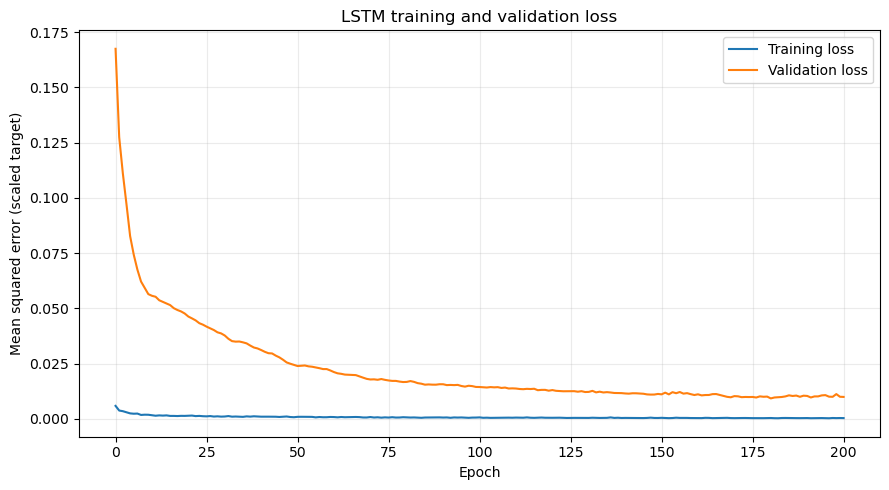

In [6]:
fig,ax=plt.subplots(figsize=(9,5))
ax.plot(history.history["loss"],label="Training loss")
ax.plot(history.history["val_loss"],label="Validation loss")
ax.set(title="LSTM training and validation loss",xlabel="Epoch",ylabel="Mean squared error (scaled target)")
ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
fig.savefig(FIGURES_DIR/"19_lstm_training_validation_loss.png",dpi=180); plt.show()

## Test predictions and approximate prediction interval

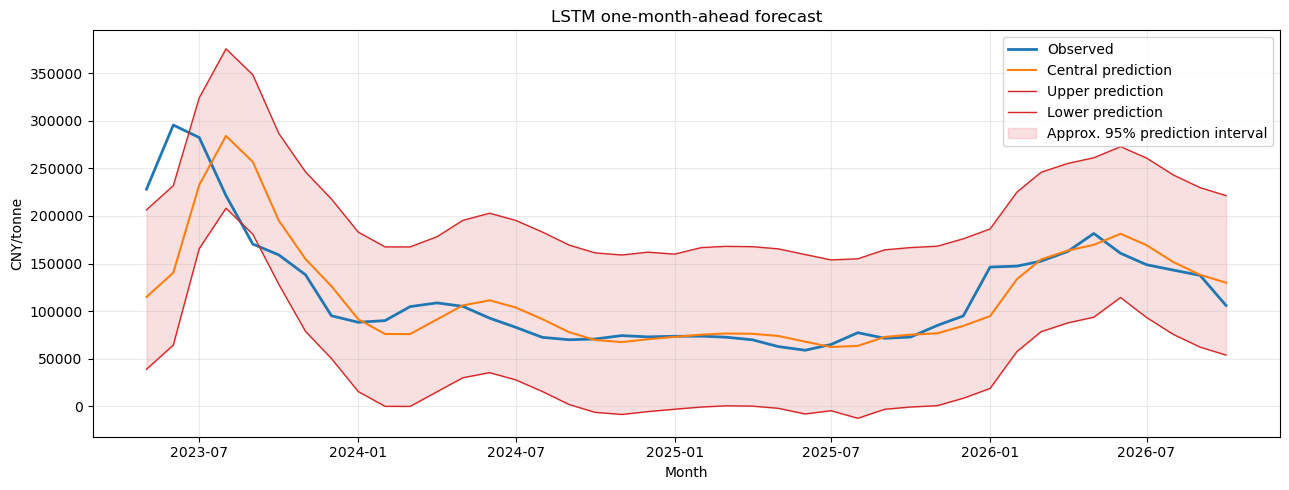

,MAE,RMSE,R2,Interval coverage
0,21874.211031,38138.833521,0.561467,0.928571


In [7]:
pred_scaled=model.predict(X_test,verbose=0).reshape(-1,1)
pred=scaler.inverse_transform(pred_scaled).ravel()
actual=scaler.inverse_transform(y_test.reshape(-1,1)).ravel()
# Calibration residuals are taken from the validation segment, not the test segment.
val_pred=model.predict(X_val,verbose=0).reshape(-1,1)
val_pred=scaler.inverse_transform(val_pred).ravel()
val_actual=scaler.inverse_transform(y_val.reshape(-1,1)).ravel()
cal_resid=val_actual-val_pred
rng=np.random.default_rng(RANDOM_STATE)
sim=np.vstack([pred + rng.choice(cal_resid,size=len(pred),replace=True) for _ in range(1500)])
lower,upper=np.quantile(sim,[.025,.975],axis=0)
fig,ax=plt.subplots(figsize=(13,5))
ax.plot(date_test,actual,label="Observed",linewidth=2)
ax.plot(date_test,pred,label="Central prediction")
ax.plot(date_test,upper,color="tab:red",linewidth=1,label="Upper prediction")
ax.plot(date_test,lower,color="tab:red",linewidth=1,label="Lower prediction")
ax.fill_between(date_test,lower,upper,color="tab:red",alpha=.14,label="Approx. 95% prediction interval")
ax.set(title="LSTM one-month-ahead forecast",xlabel="Month",ylabel="CNY/tonne")
ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
fig.savefig(FIGURES_DIR/"20_lstm_forecast_interval.png",dpi=180); plt.show()
metrics={"MAE":mean_absolute_error(actual,pred),"RMSE":mean_squared_error(actual,pred)**.5,
         "R2":r2_score(actual,pred),"Interval coverage":np.mean((actual>=lower)&(actual<=upper))}
display(pd.DataFrame([metrics]))
pd.DataFrame({"date":date_test,"actual":actual,"prediction":pred,"lower_95":lower,"upper_95":upper}).to_csv(TABLES_DIR/"lstm_1month_predictions_and_intervals.csv",index=False)

## Important caveats
- This is a deliberately small LSTM because the monthly target history is short.
- The validation segment is used for early stopping and residual calibration; the final test segment is not used for training.
- The interval is an approximate residual interval, not a formal calibrated guarantee.
- Compare this result against the univariate Random Forest, Gradient Boosting, and SVR baselines. If LSTM does not improve out-of-sample performance, report that honestly.